# BKT transition: N = 50, low E0* only (focused subset of the 9.21 scan)

Only the BKT question: vary T* at a few chosen E0* ≤ 0.3. Higher E0* drives the system into the liquid range, so it is left out.

**Data used** (existing 9.21 scan, read from `../9.21_Density Correlation/Results/structure_factors.csv`; no new runs, nothing in 9.21 is changed):
* N = 50 only. No N = 100 or 200 data exists yet, so there is no finite-size extrapolation here.
* ρ* = 0.001, 0.005, 0.01, 0.02, 0.05, 0.1. ρ* = 0.2 is dropped because it never crosses 4T* in the grid.
* E0* = 0, 0.1, 0.2, 0.25, 0.3.
* T* = 0.15 … 0.31 in steps of 0.02 (the scan grid).

Change the three lists in the next cell to choose a different subset.

**Convention (no 1/N):** $\epsilon^{-1} = 1-\kappa\,S_{QQ}(k_{\min})/(2\pi m^2)$ with $m^2=1$, $\kappa = 1/T^*$, $L=1$.
**BKT criterion:** $\epsilon^{-1} = 4T^*$. Above the line: dielectric (bound pairs). Below: conductor.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RHO_SEL = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1]
E0_SEL = [0.0, 0.1, 0.2, 0.25, 0.3]
T_MAX = 0.31

CLUSTER_FACTOR = 5.0   # clustered when S_NN(k_min) > CLUSTER_FACTOR * N (as in the other 9.21 notebooks)
DRIFT_Z = 3.0          # drifting when first/second-half S_NN(k_min) differ by > DRIFT_Z sigma

DATA_921 = Path.cwd().parent / '9.21_Density Correlation' / 'Results'   # input, read-only
RESULTS = Path.cwd() / 'Results'                                     # output of this notebook
table = pd.read_csv(DATA_921 / 'structure_factors.csv')
d = table[(table.m2 == 1) & (table.T_star <= T_MAX + 1e-9)
          & np.isclose(table.rho_star.to_numpy()[:, None], RHO_SEL).any(axis=1)
          & np.isclose(table.E0_star.to_numpy()[:, None], E0_SEL).any(axis=1)].copy()
N = int(d.N.iloc[0])
d['clustered'] = d.S_NN > CLUSTER_FACTOR * N
d['drifting'] = d.S_NN_drift_z.abs() > DRIFT_Z
d['diff_4T'] = d.inv_eps - 4 * d.T_star
T = sorted(d.T_star.unique())
print(f'N={N}; {len(d)} states = {len(RHO_SEL)} rho* x {len(E0_SEL)} E0* x {len(T)} T*;  T* = {T[0]:g} ... {T[-1]:g}')
print(f'clustered: {int(d.clustered.sum())}, drifting: {int(d.drifting.sum())}')

N=50; 270 states = 6 rho* x 5 E0* x 9 T*;  T* = 0.15 ... 0.31
clustered: 131, drifting: 52


## 1. 1/ε(k_min) vs T*, one panel per ρ*
Dashed black: BKT line 4T*. The crossing of each curve with it is T_BKT. Open markers: clustered state (1/ε is a two-phase average there).

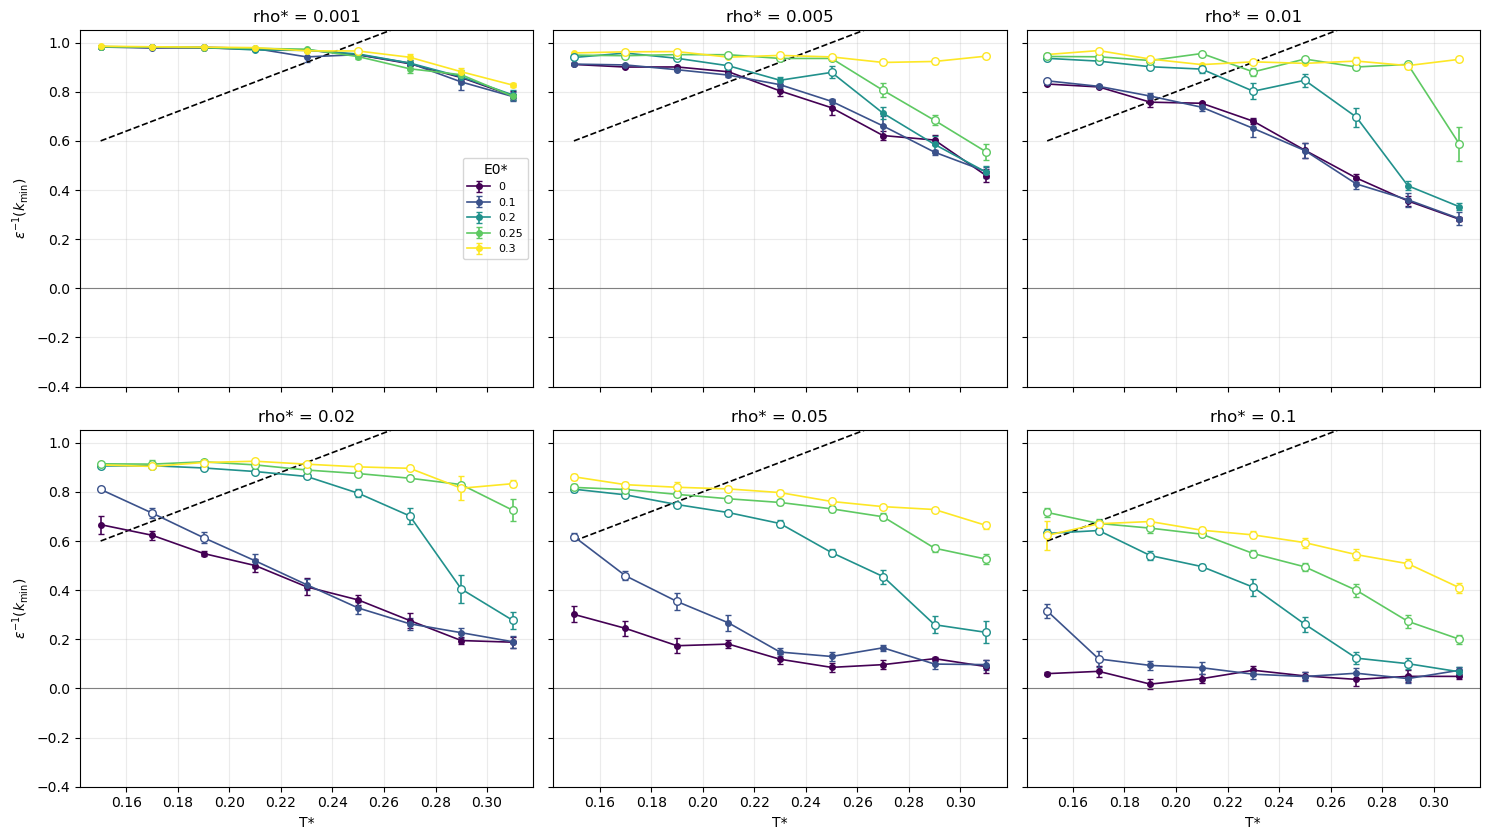

In [2]:
cmap = plt.get_cmap('viridis')
colors = {e0: cmap(i / max(len(E0_SEL) - 1, 1)) for i, e0 in enumerate(E0_SEL)}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), sharex=True, sharey=True)
tt = np.linspace(T[0], T[-1], 50)
for ax, rho in zip(axes.flat, RHO_SEL):
    for e0 in E0_SEL:
        s = d[np.isclose(d.rho_star, rho) & np.isclose(d.E0_star, e0)].sort_values('T_star')
        c = colors[e0]
        ax.errorbar(s.T_star, s.inv_eps, yerr=s.inv_eps_sem, color=c, lw=1.2, marker='o', ms=4,
                    capsize=2, label=f'{e0:g}')
        cl = s[s.clustered]
        ax.scatter(cl.T_star, cl.inv_eps, facecolors='white', edgecolors=c, s=30, zorder=3)
    ax.plot(tt, 4 * tt, 'k--', lw=1.2)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set(title=f'rho* = {rho:g}', ylim=(-0.4, 1.05)); ax.grid(alpha=0.25)
for ax in axes[1]: ax.set_xlabel('T*')
for ax in axes[:, 0]: ax.set_ylabel(r'$\epsilon^{-1}(k_{\min})$')
axes[0, 0].legend(title='E0*', fontsize=8)
fig.tight_layout(); plt.show()

## 2. T_BKT for each (ρ*, E0*)
Linear interpolation at the last + → − sign change of $\epsilon^{-1}-4T^*$ (same method as `Dielectric_Phase_Diagram.ipynb` and 9.6). Error range: repeat with $\epsilon^{-1}\pm$SEM.
`reliable` = exactly one crossing, and both bracketing states are neither clustered nor drifting.
If the curve is already below 4T* at T* = 0.15, the grid only gives an upper bound: **T_BKT < 0.15**.

In [3]:
def crossing(x, y):
    for i in reversed(range(len(x) - 1)):
        if y[i] >= 0 > y[i + 1]:
            return x[i] + (x[i + 1] - x[i]) * y[i] / (y[i] - y[i + 1]), i
    return np.nan, None

rows = []
for (rho, e0), s in d.groupby(['rho_star', 'E0_star']):
    s = s.sort_values('T_star')
    x, y, err = s.T_star.to_numpy(), s.diff_4T.to_numpy(), s.inv_eps_sem.to_numpy()
    t_c, i = crossing(x, y)
    n_cross = int(np.sum((y[:-1] >= 0) & (y[1:] < 0)))
    if i is None:
        status = f'below {x[0]:g}' if (y < 0).all() else ('above grid' if (y >= 0).all() else 'no clean crossing')
        reliable = False
    else:
        pair = s.iloc[[i, i + 1]]
        reliable = n_cross == 1 and not (pair.clustered.any() or pair.drifting.any())
        status = 'crossing'
    rows.append(dict(rho_star=rho, E0_star=e0, T_BKT=t_c, T_BKT_low=crossing(x, y - err)[0],
                     T_BKT_high=crossing(x, y + err)[0], n_crossings=n_cross, status=status, reliable=reliable))
bkt = pd.DataFrame(rows)
bkt.to_csv(RESULTS / 'bkt_focused_N50.csv', index=False)

def cell(r):
    if r.status != 'crossing':
        return '< 0.15' if r.status.startswith('below') else r.status
    return f'{r.T_BKT:.3f}' + ('' if r.reliable else ' *')
summary = bkt.assign(T=bkt.apply(cell, axis=1)).pivot(index='E0_star', columns='rho_star', values='T')
print('T_BKT   (* = flagged: bracketing state clustered/drifting, or several crossings)')
display(summary)

T_BKT   (* = flagged: bracketing state clustered/drifting, or several crossings)


rho_star,0.001,0.005,0.010,0.020,0.050,0.100
E0_star,,,,,,
0.00,0.240 *,0.215,0.190,0.161,< 0.15,< 0.15
0.10,0.236 *,0.215,0.194,0.174 *,0.152 *,< 0.15
0.20,0.240 *,0.219 *,0.216 *,0.219 *,0.188 *,0.159 *
0.25,0.240,0.234 *,0.225 *,0.224 *,0.196 *,0.169 *
0.30,0.242 *,0.236 *,0.230 *,0.228 *,0.204 *,0.164 *


## 3. T_BKT vs ρ*, one line per E0*
Filled = reliable, open = flagged. Down arrows at T* = 0.15: no crossing in the grid, so T_BKT < 0.15 there.

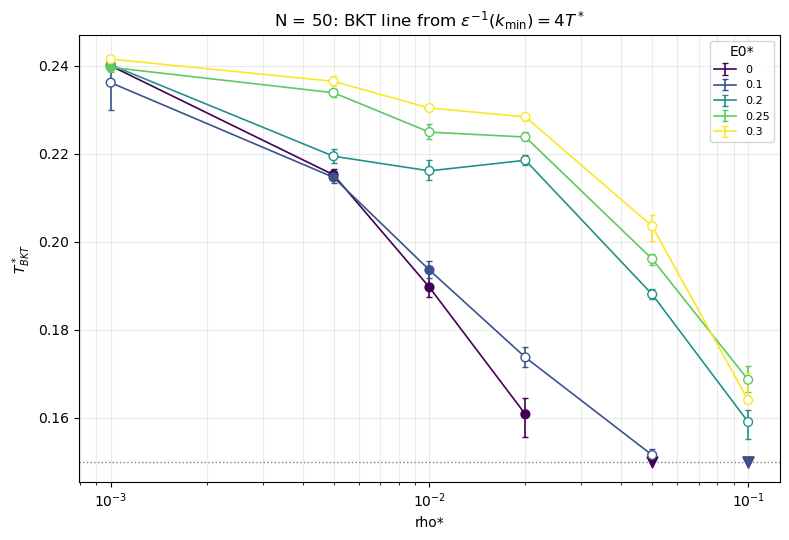

In [4]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for e0 in E0_SEL:
    c = colors[e0]
    s = bkt[np.isclose(bkt.E0_star, e0)].sort_values('rho_star')
    ok = s[s.T_BKT.notna()]
    yerr = np.array([(ok.T_BKT - ok.T_BKT_low).clip(lower=0).fillna(0),
                     (ok.T_BKT_high - ok.T_BKT).clip(lower=0).fillna(0)])
    ax.errorbar(ok.rho_star, ok.T_BKT, yerr=yerr, color=c, lw=1.2, capsize=2, label=f'{e0:g}')
    ax.scatter(ok.rho_star, ok.T_BKT, s=40, color=c, zorder=3,
               facecolors=[c if r else 'white' for r in ok.reliable])
    low = s[s.status.str.startswith('below')]
    ax.scatter(low.rho_star, np.full(len(low), T[0]), marker='v', s=60, color=c, zorder=3)
ax.axhline(T[0], color='gray', ls=':', lw=1)
ax.set(xscale='log', xlabel='rho*', ylabel=r'$T^*_{BKT}$', title=f'N = {N}: BKT line from $\\epsilon^{{-1}}(k_{{\\min}}) = 4T^*$')
ax.grid(alpha=0.25, which='both'); ax.legend(title='E0*', fontsize=8)
fig.tight_layout(); plt.show()

## 4. T_BKT vs E0*, one line per ρ*
How much the short-range Majorana term shifts the transition at each density.

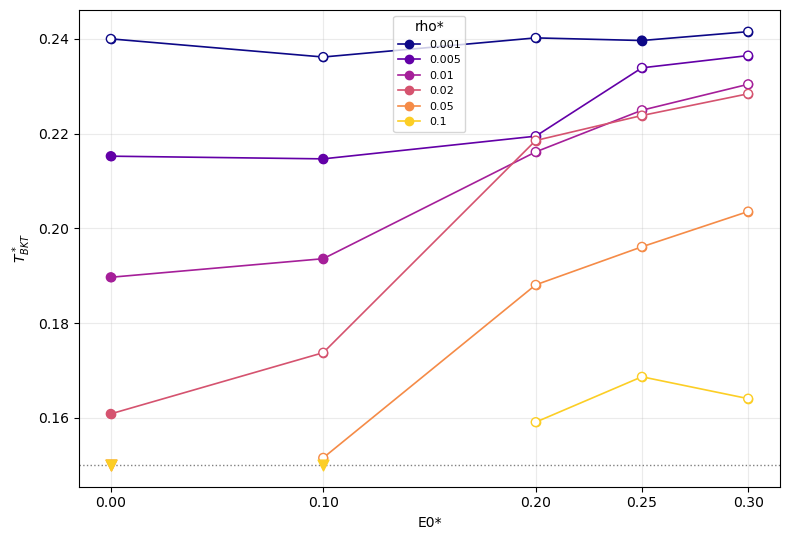

In [5]:
cmap_r = plt.get_cmap('plasma')
fig, ax = plt.subplots(figsize=(8, 5.5))
for j, rho in enumerate(RHO_SEL):
    c = cmap_r(j / max(len(RHO_SEL) - 1, 1) * 0.9)
    s = bkt[np.isclose(bkt.rho_star, rho)].sort_values('E0_star')
    ok = s[s.T_BKT.notna()]
    ax.plot(ok.E0_star, ok.T_BKT, color=c, lw=1.2, marker='o', label=f'{rho:g}')
    ax.scatter(ok.E0_star, ok.T_BKT, s=40, color=c, zorder=3,
               facecolors=[c if r else 'white' for r in ok.reliable])
    low = s[s.status.str.startswith('below')]
    ax.scatter(low.E0_star, np.full(len(low), T[0]), marker='v', s=60, color=c, zorder=3)
ax.axhline(T[0], color='gray', ls=':', lw=1)
ax.set(xlabel='E0*', ylabel=r'$T^*_{BKT}$', xticks=E0_SEL)
ax.grid(alpha=0.25); ax.legend(title='rho*', fontsize=8)
fig.tight_layout(); plt.show()

## 5. BKT phase map in the (E0*, T*) plane, one panel per ρ*
One dot per simulated state.
* **Blue:** dielectric, $\epsilon^{-1} > 4T^*$ (bound pairs). **Orange:** conductor, $\epsilon^{-1} < 4T^*$ (free charges). **Gray:** at the BKT condition within 2 SEM.
* **Ring (white fill):** clustered / droplet state, so 1/ε is a two-phase average there.
* **Small black centre dot:** drifting (the two halves of the run disagree by more than 3σ). Needs review.
* **Black line:** T_BKT(E0*) from Section 2, with diamonds filled = reliable, open = flagged. **▼** below the axis: T_BKT < 0.15.

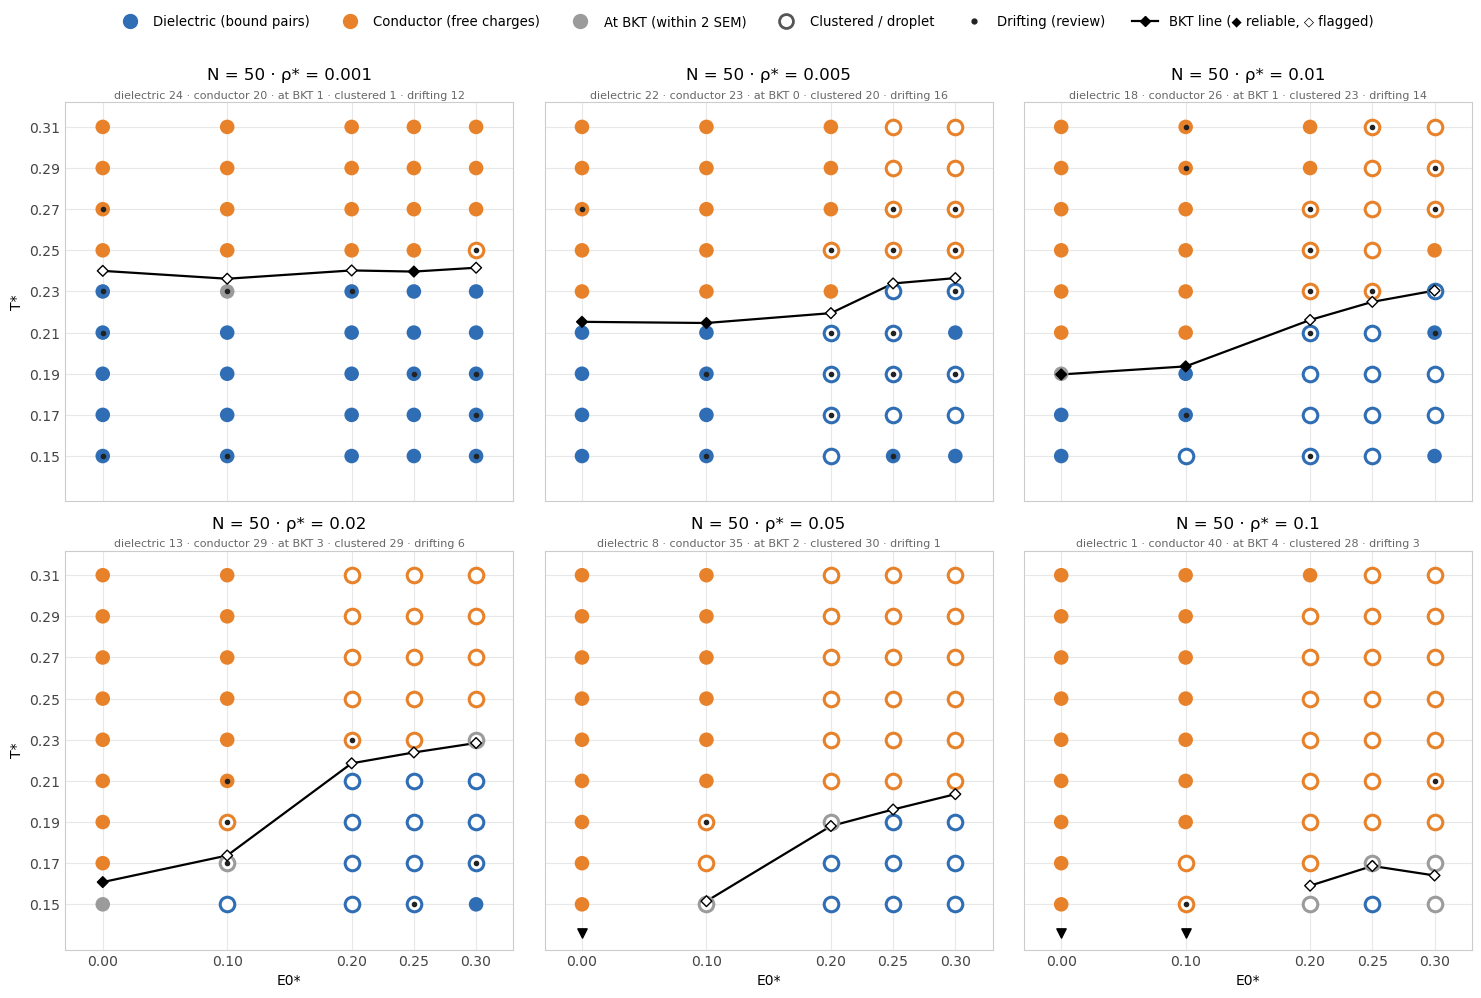

In [6]:
from matplotlib.lines import Line2D

CLASS_COLORS = {'dielectric': '#2f6db5', 'conductor': '#e8822a', 'near': '#9b9b9b'}
CLASS_LABELS = {'dielectric': 'Dielectric (bound pairs)', 'conductor': 'Conductor (free charges)',
                'near': 'At BKT (within 2 SEM)'}

def state_class(r):
    if abs(r.diff_4T) < 2 * r.inv_eps_sem:
        return 'near'
    return 'dielectric' if r.diff_4T > 0 else 'conductor'
d['phase'] = d.apply(state_class, axis=1)

fig, axes = plt.subplots(2, 3, figsize=(15, 10), sharex=True, sharey=True)
for ax, rho in zip(axes.flat, RHO_SEL):
    s = d[np.isclose(d.rho_star, rho)]
    for ph, col in CLASS_COLORS.items():
        g = s[s.phase == ph]
        ax.scatter(g[~g.clustered].E0_star, g[~g.clustered].T_star, s=110, color=col, edgecolors='none', zorder=2)
        ax.scatter(g[g.clustered].E0_star, g[g.clustered].T_star, s=110, facecolors='white',
                   edgecolors=col, linewidths=2.2, zorder=2)
    dr = s[s.drifting]
    ax.scatter(dr.E0_star, dr.T_star, s=9, color='#222222', zorder=3)
    b = bkt[np.isclose(bkt.rho_star, rho)].sort_values('E0_star')
    ok = b[b.T_BKT.notna()]
    ax.plot(ok.E0_star, ok.T_BKT, color='k', lw=1.6, zorder=1)
    ax.scatter(ok.E0_star, ok.T_BKT, marker='D', s=30, color='k', zorder=4,
               facecolors=['k' if r else 'white' for r in ok.reliable])
    low = b[b.status.str.startswith('below')]
    ax.scatter(low.E0_star, np.full(len(low), T[0] - 0.014), marker='v', s=45, color='k', zorder=4)
    n = s.phase.value_counts()
    ax.text(0.5, 1.005, f"dielectric {n.get('dielectric', 0)} · conductor {n.get('conductor', 0)} · "
            f"at BKT {n.get('near', 0)} · clustered {int(s.clustered.sum())} · drifting {int(s.drifting.sum())}",
            transform=ax.transAxes, ha='center', va='bottom', fontsize=8, color='#666666')
    ax.set(xticks=E0_SEL, yticks=T, xlim=(-0.03, 0.33), ylim=(T[0] - 0.022, T[-1] + 0.012))
    ax.set_title(f'N = {N} · ρ* = {rho:g}', fontsize=12, pad=16)
    ax.grid(color='#e8e8e8', lw=0.8); ax.set_axisbelow(True)
    for sp in ax.spines.values(): sp.set_color('#cccccc')
    ax.tick_params(colors='#444444', length=0)
for ax in axes[1]: ax.set_xlabel('E0*')
for ax in axes[:, 0]: ax.set_ylabel('T*')
handles = [Line2D([], [], marker='o', ls='', ms=10, color=c, label=CLASS_LABELS[k]) for k, c in CLASS_COLORS.items()]
handles += [Line2D([], [], marker='o', ls='', ms=10, mfc='white', mec='#555555', mew=2, label='Clustered / droplet'),
            Line2D([], [], marker='o', ls='', ms=3.5, color='#222222', label='Drifting (review)'),
            Line2D([], [], color='k', lw=1.6, marker='D', ms=5, label='BKT line (◆ reliable, ◇ flagged)')]
fig.legend(handles=handles, loc='upper center', ncol=6, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

## 6. Limits of this subset
* **One system size.** With N = 50 only, these are finite-size crossings, not T_BKT(∞). Runs at N = 100 and 200 on the same grid would allow the extrapolation $T(L)=T_{BKT}+c/(\ln L)^2$ with $L/\sigma=\sqrt{N/\rho^*}$.
* **T* grid starts at 0.15.** At high ρ* and low E0* the transition lies below the grid (down arrows). Only an upper bound is known there.
* **Flagged points** (open markers, `*`): a bracketing state is clustered or drifting, so 1/ε mixes two phases. Treat those T_BKT values as rough.